In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE = "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results"

conj40 = pd.read_csv(
    f"{BASE}/conj40_forward_freeze_sweep.csv"
)

conj5 = pd.read_csv(
    f"{BASE}/conj5_forward_freeze_sweep.csv"
)

disj40 = pd.read_csv(
    f"{BASE}/disj40_forward_freeze_sweep.csv"
)

disj5 = pd.read_csv(
    f"{BASE}/disj5_forward_freeze_sweep.csv"
)
# Keep successful runs only
conj = conj[conj["error"].isna()].copy()
disj = disj[disj["error"].isna()].copy()

print("Conj rows:", len(conj))
print("Disj rows:", len(disj))

# ==========================================================
# SANITY CHECK BASELINES
# ==========================================================

conj_base_examples = (
    conj.drop_duplicates(["trial", "target_present"])
)

disj_base_examples = (
    disj.drop_duplicates(["trial", "target_present"])
)

print("\nConjunctive:")
print("N =", len(conj_base_examples))
print(
    "Baseline accuracy =",
    conj_base_examples["baseline_correct"].mean()
)
print(
    "Baseline True rate =",
    conj_base_examples["baseline_prediction"].mean()
)

print("\nDisjunctive:")
print("N =", len(disj_base_examples))
print(
    "Baseline accuracy =",
    disj_base_examples["baseline_correct"].mean()
)
print(
    "Baseline True rate =",
    disj_base_examples["baseline_prediction"].mean()
)

Conj rows: 2700
Disj rows: 2700

Conjunctive:
N = 100
Baseline accuracy = 0.62
Baseline True rate = 0.56

Disjunctive:
N = 100
Baseline accuracy = 1.0
Baseline True rate = 0.5


Conj 40 rows: 2700
Conj 5 rows: 2700
Disj 40 rows: 2700
Disj 5 rows: 2700

Conjunctive 40:
N = 100
Baseline accuracy = 0.62
Baseline True rate = 0.56

Conjunctive 5:
N = 100
Baseline accuracy = 0.81
Baseline True rate = 0.37

Disjunctive 40:
N = 100
Baseline accuracy = 1.0
Baseline True rate = 0.5

Disjunctive 5:
N = 100
Baseline accuracy = 1.0
Baseline True rate = 0.5

BASELINE SUMMARY
Conjunctive 5:  0.810
Conjunctive 40: 0.620
Disjunctive 5:  1.000
Disjunctive 40: 1.000


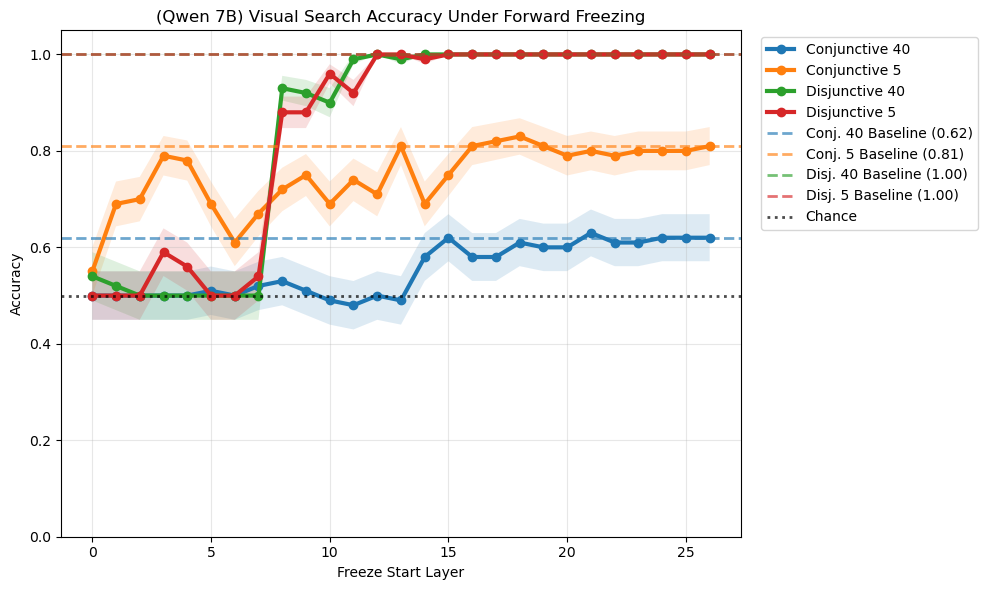

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE = "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results"

# ==========================================================
# LOAD DATA
# ==========================================================



# ==========================================================
# KEEP SUCCESSFUL RUNS ONLY
# ==========================================================

conj40 = conj40[conj40["error"].isna()].copy()
conj5 = conj5[conj5["error"].isna()].copy()
disj40 = disj40[disj40["error"].isna()].copy()
disj5 = disj5[disj5["error"].isna()].copy()

print("Conj 40 rows:", len(conj40))
print("Conj 5 rows:", len(conj5))
print("Disj 40 rows:", len(disj40))
print("Disj 5 rows:", len(disj5))


# ==========================================================
# SANITY CHECK BASELINES
# ==========================================================

def baseline_summary(df, name):

    base_examples = (
        df.drop_duplicates(["trial", "target_present"])
    )

    print(f"\n{name}:")
    print("N =", len(base_examples))
    print(
        "Baseline accuracy =",
        base_examples["baseline_correct"].mean()
    )
    print(
        "Baseline True rate =",
        base_examples["baseline_prediction"].mean()
    )

    return base_examples


conj40_base_examples = baseline_summary(
    conj40,
    "Conjunctive 40"
)

conj5_base_examples = baseline_summary(
    conj5,
    "Conjunctive 5"
)

disj40_base_examples = baseline_summary(
    disj40,
    "Disjunctive 40"
)

disj5_base_examples = baseline_summary(
    disj5,
    "Disjunctive 5"
)


# ==========================================================
# BASELINE ACCURACIES
# ==========================================================

conj40_baseline = (
    conj40_base_examples["baseline_correct"].mean()
)

conj5_baseline = (
    conj5_base_examples["baseline_correct"].mean()
)

disj40_baseline = (
    disj40_base_examples["baseline_correct"].mean()
)

disj5_baseline = (
    disj5_base_examples["baseline_correct"].mean()
)

print("\n========================================")
print("BASELINE SUMMARY")
print("========================================")

print(f"Conjunctive 5:  {conj5_baseline:.3f}")
print(f"Conjunctive 40: {conj40_baseline:.3f}")
print(f"Disjunctive 5:  {disj5_baseline:.3f}")
print(f"Disjunctive 40: {disj40_baseline:.3f}")


# ==========================================================
# SUMMARIZE FORWARD FREEZING
# ==========================================================

def accuracy_summary(df):

    out = (
        df.groupby("source_layer")["patched_correct"]
        .agg(["mean", "std", "count"])
        .reset_index()
    )

    out["sem"] = (
        out["std"] / np.sqrt(out["count"])
    )

    return out


conj40_acc = accuracy_summary(conj40)
conj5_acc = accuracy_summary(conj5)
disj40_acc = accuracy_summary(disj40)
disj5_acc = accuracy_summary(disj5)


# ==========================================================
# PLOT
# ==========================================================

plt.figure(figsize=(10, 6))

# ----------------------------------------------------------
# Conjunctive 40
# ----------------------------------------------------------

line_c40, = plt.plot(
    conj40_acc["source_layer"],
    conj40_acc["mean"],
    marker="o",
    linewidth=3,
    label="Conjunctive 40",
)

plt.fill_between(
    conj40_acc["source_layer"],
    conj40_acc["mean"] - conj40_acc["sem"],
    conj40_acc["mean"] + conj40_acc["sem"],
    alpha=0.15,
)


# ----------------------------------------------------------
# Conjunctive 5
# ----------------------------------------------------------

line_c5, = plt.plot(
    conj5_acc["source_layer"],
    conj5_acc["mean"],
    marker="o",
    linewidth=3,
    label="Conjunctive 5",
)

plt.fill_between(
    conj5_acc["source_layer"],
    conj5_acc["mean"] - conj5_acc["sem"],
    conj5_acc["mean"] + conj5_acc["sem"],
    alpha=0.15,
)


# ----------------------------------------------------------
# Disjunctive 40
# ----------------------------------------------------------

line_d40, = plt.plot(
    disj40_acc["source_layer"],
    disj40_acc["mean"],
    marker="o",
    linewidth=3,
    label="Disjunctive 40",
)

plt.fill_between(
    disj40_acc["source_layer"],
    disj40_acc["mean"] - disj40_acc["sem"],
    disj40_acc["mean"] + disj40_acc["sem"],
    alpha=0.15,
)


# ----------------------------------------------------------
# Disjunctive 5
# ----------------------------------------------------------

line_d5, = plt.plot(
    disj5_acc["source_layer"],
    disj5_acc["mean"],
    marker="o",
    linewidth=3,
    label="Disjunctive 5",
)

plt.fill_between(
    disj5_acc["source_layer"],
    disj5_acc["mean"] - disj5_acc["sem"],
    disj5_acc["mean"] + disj5_acc["sem"],
    alpha=0.15,
)


# ==========================================================
# ORIGINAL BASELINES
# ==========================================================

plt.axhline(
    conj40_baseline,
    color=line_c40.get_color(),
    linestyle="--",
    linewidth=2,
    alpha=0.65,
    label=f"Conj. 40 Baseline ({conj40_baseline:.2f})",
)

plt.axhline(
    conj5_baseline,
    color=line_c5.get_color(),
    linestyle="--",
    linewidth=2,
    alpha=0.65,
    label=f"Conj. 5 Baseline ({conj5_baseline:.2f})",
)

plt.axhline(
    disj40_baseline,
    color=line_d40.get_color(),
    linestyle="--",
    linewidth=2,
    alpha=0.65,
    label=f"Disj. 40 Baseline ({disj40_baseline:.2f})",
)

plt.axhline(
    disj5_baseline,
    color=line_d5.get_color(),
    linestyle="--",
    linewidth=2,
    alpha=0.65,
    label=f"Disj. 5 Baseline ({disj5_baseline:.2f})",
)


# ----------------------------------------------------------
# Chance
# ----------------------------------------------------------

plt.axhline(
    0.5,
    color="black",
    linestyle=":",
    linewidth=2,
    alpha=0.7,
    label="Chance",
)


# ==========================================================
# FORMATTING
# ==========================================================

plt.xlabel("Freeze Start Layer")
plt.ylabel("Accuracy")

plt.title(
    "(Qwen 7B) Visual Search Accuracy Under Forward Freezing"
)

plt.ylim(0, 1.05)

plt.grid(alpha=0.3)
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

Loading: /oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/conj5_forward_freeze_sweep.csv
Loading: /oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/conj10_forward_freeze_sweep.csv
Loading: /oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/conj15_forward_freeze_sweep.csv
Loading: /oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/conj20_forward_freeze_sweep.csv
Loading: /oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/conj25_forward_freeze_sweep.csv
Loading: /oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/conj30_forward_freeze_sweep.csv
Loading: /oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/conj35_forward_freeze_sweep.csv
Loading: /oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/conj40_forward_freeze_sweep.csv
Loading: /oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/disj5_forward_freeze_sweep.csv
Loading: /oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/disj10_forward_freeze_sw

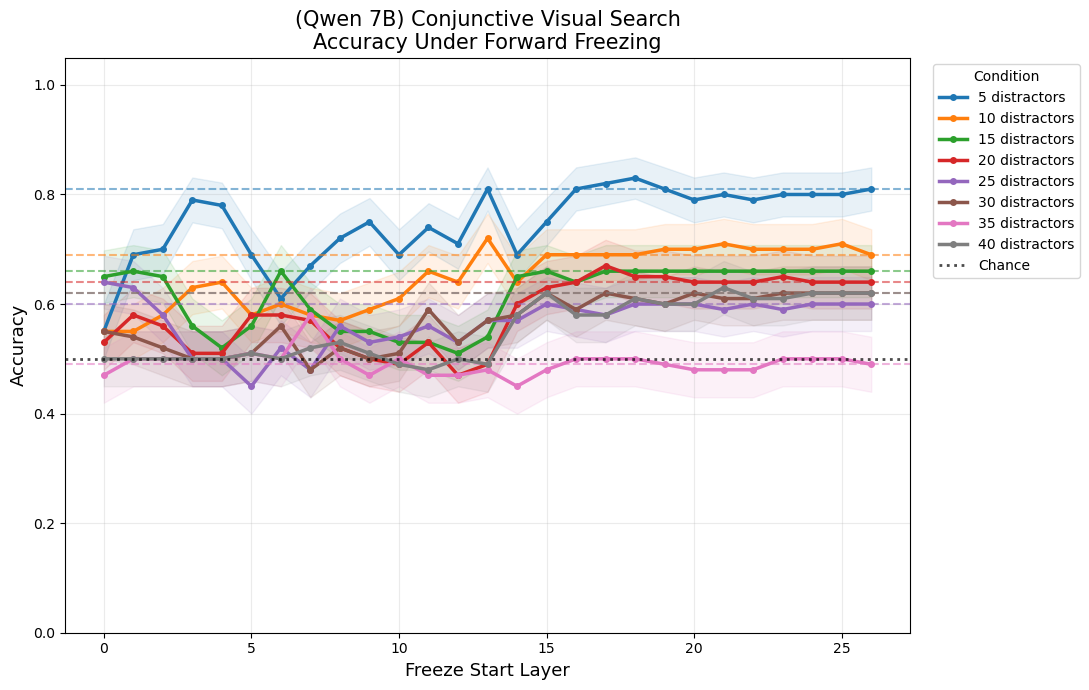

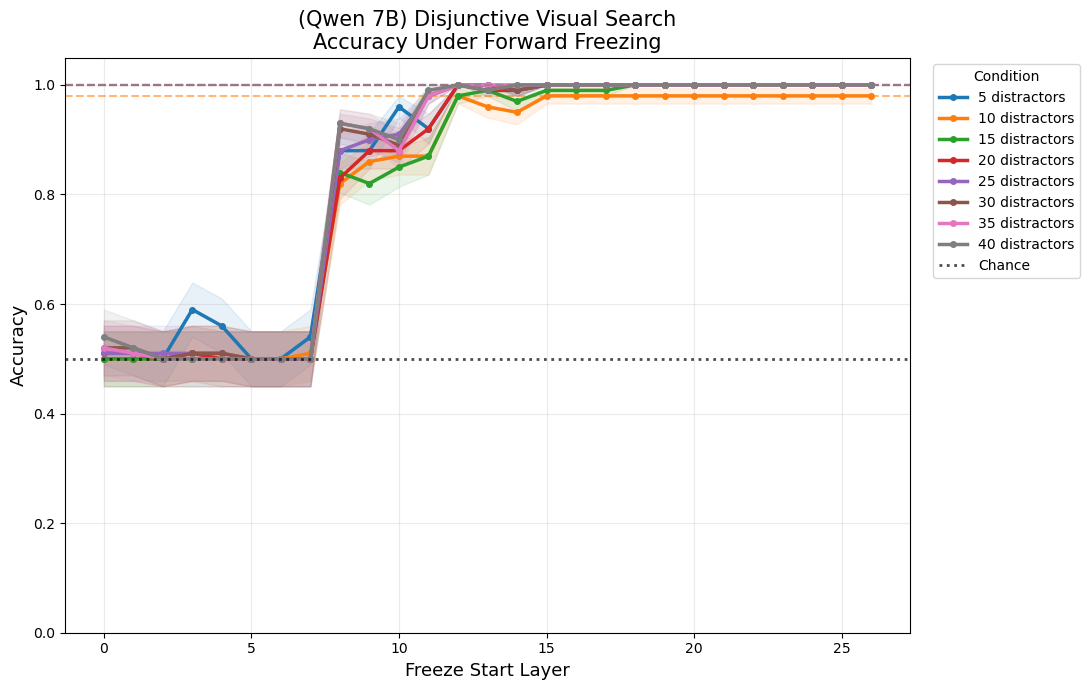

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==========================================================
# CONFIG
# ==========================================================

BASE = "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results"

DISTRACTOR_COUNTS = [5, 10, 15, 20, 25, 30, 35, 40]


# ==========================================================
# LOAD DATA
# ==========================================================

def load_condition(condition, short_name):
    """
    Load all distractor-count forward-freezing results for one condition.

    condition:
        "Conjunctive" or "Disjunctive"

    short_name:
        "conj" or "disj"
    """

    dfs = {}

    for n in DISTRACTOR_COUNTS:

        path = (
            f"{BASE}/"
            f"{short_name}{n}_forward_freeze_sweep.csv"
        )

        print(f"Loading: {path}")

        df = pd.read_csv(path)

        # Keep successful interventions only
        df = df[df["error"].isna()].copy()

        dfs[n] = df

    return dfs


conj = load_condition(
    condition="Conjunctive",
    short_name="conj",
)

disj = load_condition(
    condition="Disjunctive",
    short_name="disj",
)


# ==========================================================
# SANITY CHECK BASELINES
# ==========================================================

def get_baseline(df):
    """
    Each image appears once per source layer, so remove those
    duplicate intervention rows before computing baseline accuracy.
    """

    base_examples = (
        df.drop_duplicates(
            ["trial", "target_present"]
        )
    )

    return {
        "n": len(base_examples),
        "accuracy": base_examples["baseline_correct"].mean(),
        "true_rate": base_examples["baseline_prediction"].mean(),
    }


def print_baselines(datasets, condition_name):

    print("\n" + "=" * 60)
    print(f"{condition_name.upper()} BASELINES")
    print("=" * 60)

    baselines = {}

    for n, df in datasets.items():

        summary = get_baseline(df)
        baselines[n] = summary["accuracy"]

        print(
            f"{n:2d} distractors | "
            f"N={summary['n']:3d} | "
            f"Accuracy={summary['accuracy']:.3f} | "
            f"True rate={summary['true_rate']:.3f}"
        )

    return baselines


conj_baselines = print_baselines(
    conj,
    "Conjunctive",
)

disj_baselines = print_baselines(
    disj,
    "Disjunctive",
)


# ==========================================================
# SUMMARIZE FORWARD FREEZING
# ==========================================================

def accuracy_summary(df):

    out = (
        df.groupby("source_layer")["patched_correct"]
        .agg(["mean", "std", "count"])
        .reset_index()
    )

    out["sem"] = (
        out["std"] / np.sqrt(out["count"])
    )

    return out


conj_acc = {
    n: accuracy_summary(df)
    for n, df in conj.items()
}

disj_acc = {
    n: accuracy_summary(df)
    for n, df in disj.items()
}


# ==========================================================
# PLOTTING FUNCTION
# ==========================================================

def plot_condition(
    summaries,
    baselines,
    condition_name,
):

    plt.figure(figsize=(11, 7))

    # ------------------------------------------------------
    # Plot each distractor count
    # ------------------------------------------------------

    for n in DISTRACTOR_COUNTS:

        summary = summaries[n]

        line, = plt.plot(
            summary["source_layer"],
            summary["mean"],
            marker="o",
            markersize=4,
            linewidth=2.5,
            label=f"{n} distractors",
        )

        # SEM shading
        plt.fill_between(
            summary["source_layer"],
            summary["mean"] - summary["sem"],
            summary["mean"] + summary["sem"],
            color=line.get_color(),
            alpha=0.10,
        )

        # Original baseline for this distractor count
        plt.axhline(
            baselines[n],
            color=line.get_color(),
            linestyle="--",
            linewidth=1.5,
            alpha=0.55,
        )

    # ------------------------------------------------------
    # Chance
    # ------------------------------------------------------

    plt.axhline(
        0.5,
        color="black",
        linestyle=":",
        linewidth=2,
        alpha=0.7,
        label="Chance",
    )

    # ------------------------------------------------------
    # Formatting
    # ------------------------------------------------------

    plt.xlabel(
        "Freeze Start Layer",
        fontsize=13,
    )

    plt.ylabel(
        "Accuracy",
        fontsize=13,
    )

    plt.title(
        f"(Qwen 7B) {condition_name} Visual Search\n"
        "Accuracy Under Forward Freezing",
        fontsize=15,
    )

    plt.ylim(0, 1.05)

    plt.grid(
        alpha=0.25
    )

    plt.legend(
        title="Condition",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
    )

    plt.tight_layout()

    plt.show()


# ==========================================================
# CONJUNCTIVE PLOT
# ==========================================================

plot_condition(
    summaries=conj_acc,
    baselines=conj_baselines,
    condition_name="Conjunctive",
)


# ==========================================================
# DISJUNCTIVE PLOT
# ==========================================================

plot_condition(
    summaries=disj_acc,
    baselines=disj_baselines,
    condition_name="Disjunctive",
)

Conjunctive baseline preference: 0.374
Disjunctive baseline preference: 6.615


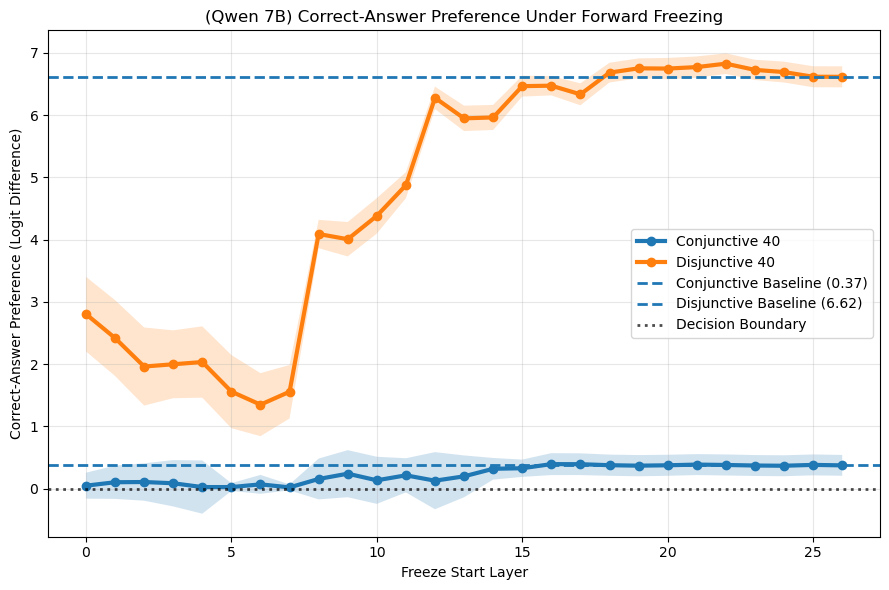

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================================
# SUMMARIZE RAW GT PREFERENCE
# ==========================================================

def preference_summary(df):
    out = (
        df.groupby("source_layer")["patched_gt_preference"]
        .agg(["mean", "std", "count"])
        .reset_index()
    )

    out["sem"] = out["std"] / np.sqrt(out["count"])

    return out


conj_pref = preference_summary(conj)
disj_pref = preference_summary(disj)


# ==========================================================
# BASELINE GT PREFERENCE
# ==========================================================

# Baseline is repeated for every source layer,
# so retain only one copy of each example.

conj_base_examples = (
    conj.drop_duplicates(["trial", "target_present"])
)

disj_base_examples = (
    disj.drop_duplicates(["trial", "target_present"])
)

conj_baseline_pref = (
    conj_base_examples["baseline_gt_preference"].mean()
)

disj_baseline_pref = (
    disj_base_examples["baseline_gt_preference"].mean()
)

print(
    f"Conjunctive baseline preference: "
    f"{conj_baseline_pref:.3f}"
)

print(
    f"Disjunctive baseline preference: "
    f"{disj_baseline_pref:.3f}"
)


# ==========================================================
# PLOT
# ==========================================================

plt.figure(figsize=(9, 6))


# --------------------------
# Conjunctive
# --------------------------

plt.plot(
    conj_pref["source_layer"],
    conj_pref["mean"],
    marker="o",
    linewidth=3,
    label="Conjunctive 40",
)

plt.fill_between(
    conj_pref["source_layer"],
    conj_pref["mean"] - conj_pref["sem"],
    conj_pref["mean"] + conj_pref["sem"],
    alpha=0.20,
)


# --------------------------
# Disjunctive
# --------------------------

plt.plot(
    disj_pref["source_layer"],
    disj_pref["mean"],
    marker="o",
    linewidth=3,
    label="Disjunctive 40",
)

plt.fill_between(
    disj_pref["source_layer"],
    disj_pref["mean"] - disj_pref["sem"],
    disj_pref["mean"] + disj_pref["sem"],
    alpha=0.20,
)


# ==========================================================
# UNPATCHED BASELINES
# ==========================================================

plt.axhline(
    conj_baseline_pref,
    linestyle="--",
    linewidth=2,
    label=(
        f"Conjunctive Baseline "
        f"({conj_baseline_pref:.2f})"
    ),
)

plt.axhline(
    disj_baseline_pref,
    linestyle="--",
    linewidth=2,
    label=(
        f"Disjunctive Baseline "
        f"({disj_baseline_pref:.2f})"
    ),
)


# ==========================================================
# DECISION BOUNDARY
# ==========================================================

plt.axhline(
    0,
    color="black",
    linestyle=":",
    linewidth=2,
    alpha=0.7,
    label="Decision Boundary",
)


# ==========================================================
# FORMATTING
# ==========================================================

plt.xlabel("Freeze Start Layer")
plt.ylabel("Correct-Answer Preference (Logit Difference)")

plt.title(
    "(Qwen 7B) Correct-Answer Preference Under Forward Freezing"
)

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()